# HV-008 — Dynamic Step Response

**Technical gate:** SR-001  
**Dataset release:** VSM-LAB-DATA-v1.1

This notebook characterizes the DUT response to commanded 30↔70 %RH step transitions.

The analysis separates:

1. command-to-response timing; and
2. DUT lag relative to the measured RH reference.

This prevents chamber dynamics from being misattributed to the DUT.

## 1. Engineering Question

> How quickly and consistently does the RH DUT respond to a commanded step across temperature, direction, and repetition, and how much lag does it exhibit relative to the measured reference trajectory?

Final HVAC suitability is not decided in this notebook.

## 2. Reproducible Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

current_dir = Path.cwd()
candidate_roots = [current_dir, *current_dir.parents]

project_root = next(
    (
        path
        for path in candidate_roots
        if (path / "data" / "raw" / "vsm_lab_data_v1_1").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate project root containing "
        "'data/raw/vsm_lab_data_v1_1'."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.step_response_analysis import (
    build_step_metrics_table,
    load_dynamic_step,
)

tables_dir = project_root / "reports" / "tables"
figures_dir = project_root / "reports" / "figures"
tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print(f"Project root: {project_root}")

Project root: /home/runner/work/hvac-sensor-validation-metrology/hvac-sensor-validation-metrology


## 3. SR-01 — Dynamic-Step Dataset Audit

Expected design:

- 30 Test_IDs;
- 9,030 rows;
- 301 samples/Test_ID;
- 1 Hz sampling;
- 0–300 s elapsed time;
- command transition at 60 s;
- temperatures 15/25/35 °C;
- UP and DOWN directions;
- five repetitions per Temperature × Direction condition.

In [2]:
step_df, test_matrix_df = load_dynamic_step(project_root)

step_matrix_df = test_matrix_df.loc[
    test_matrix_df["Test_Family"].astype(str).str.upper().eq("DYNAMIC_STEP")
].copy()

group_sizes = step_df.groupby("Test_ID").size()

print("Dynamic-step dataset audit")
print("--------------------------")
print(f"Measurement rows      : {len(step_df)}")
print(f"Measurement Test_IDs  : {step_df['Test_ID'].nunique()}")
print(f"Matrix Test_IDs       : {step_matrix_df['Test_ID'].nunique()}")
print(f"Samples/Test_ID       : {sorted(group_sizes.unique().tolist())}")
print(
    "Temperatures C       : "
    f"{sorted(step_df['Temperature_Setpoint_C'].unique().tolist())}"
)
print(
    "Directions           : "
    f"{sorted(step_df['Direction'].astype(str).str.upper().unique().tolist())}"
)
print(
    "Repetitions          : "
    f"{sorted(step_df['Repetition'].unique().tolist())}"
)

assert len(step_df) == 9030
assert step_df["Test_ID"].nunique() == 30
assert step_matrix_df["Test_ID"].nunique() == 30
assert sorted(group_sizes.unique().tolist()) == [301]
assert sorted(step_df["Temperature_Setpoint_C"].unique().tolist()) == [15.0, 25.0, 35.0]
assert set(step_df["Direction"].astype(str).str.upper().unique()) == {"UP", "DOWN"}
assert sorted(step_df["Repetition"].unique().tolist()) == [1, 2, 3, 4, 5]

print("\nSR-01 dataset audit: PASS")

Dynamic-step dataset audit
--------------------------
Measurement rows      : 9030
Measurement Test_IDs  : 30
Matrix Test_IDs       : 30
Samples/Test_ID       : [301]
Temperatures C       : [15.0, 25.0, 35.0]
Directions           : ['DOWN', 'UP']
Repetitions          : [1, 2, 3, 4, 5]

SR-01 dataset audit: PASS


## 4. SR-02 — Command Transition Verification

The transition time is detected from `RH_Command`, not assumed.

Expected design value:

```text
t_command = 60 s
```

In [3]:
transition_rows = []

for test_id, group in step_df.groupby("Test_ID"):
    g = group.sort_values("Elapsed_s")
    initial_command = float(g["RH_Command"].iloc[0])
    changed = ~np.isclose(
        g["RH_Command"].to_numpy(dtype=float),
        initial_command,
        rtol=0.0,
        atol=1e-12,
    )
    idx = np.flatnonzero(changed)
    if idx.size == 0:
        raise ValueError(f"{test_id}: no command transition detected.")
    t_command = float(g["Elapsed_s"].iloc[idx[0]])

    transition_rows.append(
        {
            "Test_ID": test_id,
            "Temperature_Setpoint_C": float(g["Temperature_Setpoint_C"].iloc[0]),
            "Direction": str(g["Direction"].iloc[0]).upper(),
            "Repetition": int(g["Repetition"].iloc[0]),
            "Initial_Command": initial_command,
            "Final_Command": float(g["RH_Command"].iloc[-1]),
            "t_command_s": t_command,
        }
    )

transition_df = pd.DataFrame(transition_rows)

display(transition_df.head())

assert transition_df["t_command_s"].nunique() == 1
assert np.isclose(transition_df["t_command_s"].iloc[0], 60.0)

print("\nSR-02 command transition verification: PASS")

,Test_ID,Temperature_Setpoint_C,Direction,Repetition,Initial_Command,Final_Command,t_command_s
0,DY-STEP-001,15.0,UP,1,30.0,70.0,60.0
1,DY-STEP-002,15.0,UP,2,30.0,70.0,60.0
2,DY-STEP-003,15.0,UP,3,30.0,70.0,60.0
3,DY-STEP-004,15.0,UP,4,30.0,70.0,60.0
4,DY-STEP-005,15.0,UP,5,30.0,70.0,60.0



SR-02 command transition verification: PASS


## 5. SR-03 — Per-Test Step Metrics

For each Test_ID, the notebook extracts the full metric set separately for the reference and DUT:

- t10 / operational dead time;
- first-order-equivalent τ at 63.2%;
- t90;
- ±2% settling time;
- overshoot;
- DUT-minus-reference lag at t10, τ, and t90.

Initial and final levels use robust median plateau estimates.

In [4]:
step_metrics_df = build_step_metrics_table(step_df)

print(f"Metric rows: {len(step_metrics_df)}")
assert len(step_metrics_df) == 30
assert step_metrics_df["Test_ID"].nunique() == 30
assert np.allclose(step_metrics_df["t_command_s"], 60.0)

display(
    step_metrics_df[
        [
            "Test_ID",
            "Temperature_Setpoint_C",
            "Direction",
            "Repetition",
            "Reference_dead_time_s",
            "DUT_dead_time_s",
            "Reference_tau_s",
            "DUT_tau_s",
            "Reference_t90_s",
            "DUT_t90_s",
            "Lag_t10_s",
            "Lag_tau_s",
            "Lag_t90_s",
            "DUT_settling_time_s",
            "DUT_overshoot_pct",
        ]
    ].head(10).round(3)
)

print("\nSR-03 per-Test_ID metric extraction: PASS")

Metric rows: 30


,Test_ID,Temperature_Setpoint_C,Direction,Repetition,Reference_dead_time_s,DUT_dead_time_s,Reference_tau_s,DUT_tau_s,Reference_t90_s,DUT_t90_s,Lag_t10_s,Lag_tau_s,Lag_t90_s,DUT_settling_time_s,DUT_overshoot_pct
0,DY-STEP-016,15.0,DOWN,1,8.153,17.743,35.813,59.852,75.505,104.800,9.590,24.039,29.295,165.0,1.244
1,DY-STEP-017,15.0,DOWN,2,8.130,17.969,35.839,59.437,75.063,104.536,9.839,23.598,29.473,180.0,0.994
2,DY-STEP-018,15.0,DOWN,3,8.114,17.958,35.771,60.241,75.465,103.917,9.844,24.470,28.452,168.0,1.491
3,DY-STEP-019,15.0,DOWN,4,8.204,17.562,35.721,59.429,75.033,103.750,9.358,23.707,28.717,169.0,1.366
4,DY-STEP-020,15.0,DOWN,5,8.211,18.550,35.893,60.155,75.379,102.875,10.339,24.262,27.496,189.0,1.739
5,DY-STEP-001,15.0,UP,1,8.515,20.769,38.697,69.350,81.243,121.270,12.254,30.653,40.027,187.0,0.872
6,DY-STEP-002,15.0,UP,2,8.543,20.210,38.902,69.166,82.035,120.064,11.667,30.264,38.029,194.0,1.623
7,DY-STEP-003,15.0,UP,3,8.505,20.388,38.758,68.458,80.737,117.825,11.882,29.700,37.088,196.0,0.999
8,DY-STEP-004,15.0,UP,4,8.523,20.500,38.656,69.185,81.065,120.000,11.977,30.529,38.935,191.0,1.500
9,DY-STEP-005,15.0,UP,5,8.601,20.555,38.611,68.211,81.605,117.738,11.954,29.601,36.133,179.0,1.496



SR-03 per-Test_ID metric extraction: PASS


## 6. SR-04 — Metric Completeness Audit

A missing settling-time value is retained as NaN if the response does not enter and remain inside the ±2% band before the record ends. Other threshold metrics should normally be finite.

In [5]:
metric_columns = [
    "Reference_dead_time_s",
    "DUT_dead_time_s",
    "Reference_tau_s",
    "DUT_tau_s",
    "Reference_t90_s",
    "DUT_t90_s",
    "Lag_t10_s",
    "Lag_tau_s",
    "Lag_t90_s",
]

completeness = pd.DataFrame(
    {
        "Metric": metric_columns
        + ["Reference_settling_time_s", "DUT_settling_time_s"],
        "N_Finite": [
            int(np.isfinite(step_metrics_df[col]).sum())
            for col in metric_columns
        ]
        + [
            int(np.isfinite(step_metrics_df["Reference_settling_time_s"]).sum()),
            int(np.isfinite(step_metrics_df["DUT_settling_time_s"]).sum()),
        ],
    }
)
completeness["N_Total"] = len(step_metrics_df)
completeness["N_Missing"] = (
    completeness["N_Total"] - completeness["N_Finite"]
)

display(completeness)

assert (completeness.loc[
    completeness["Metric"].isin(metric_columns),
    "N_Missing",
] == 0).all()

print("\nSR-04 metric completeness audit: PASS")

,Metric,N_Finite,N_Total,N_Missing
0,Reference_dead_time_s,30,30,0
1,DUT_dead_time_s,30,30,0
2,Reference_tau_s,30,30,0
3,DUT_tau_s,30,30,0
4,Reference_t90_s,30,30,0
5,DUT_t90_s,30,30,0
6,Lag_t10_s,30,30,0
7,Lag_tau_s,30,30,0
8,Lag_t90_s,30,30,0
9,Reference_settling_time_s,30,30,0



SR-04 metric completeness audit: PASS


## 7. SR-05 — Condition-Level Summary

Five repetitions are available at each Temperature × Direction condition.

The condition summary reports mean, SD, median, min, and max for the main dynamic metrics.

In [6]:
summary_metrics = [
    "Reference_dead_time_s",
    "DUT_dead_time_s",
    "Reference_tau_s",
    "DUT_tau_s",
    "Reference_t90_s",
    "DUT_t90_s",
    "Lag_t10_s",
    "Lag_tau_s",
    "Lag_t90_s",
    "Reference_settling_time_s",
    "DUT_settling_time_s",
    "Reference_overshoot_pct",
    "DUT_overshoot_pct",
]

condition_rows = []
for (temp, direction), group in step_metrics_df.groupby(
    ["Temperature_Setpoint_C", "Direction"]
):
    row = {
        "Temperature_Setpoint_C": temp,
        "Direction": direction,
        "N": len(group),
    }
    for metric in summary_metrics:
        values = group[metric]
        row[f"{metric}_Mean"] = values.mean()
        row[f"{metric}_SD"] = values.std(ddof=1)
        row[f"{metric}_Median"] = values.median()
        row[f"{metric}_Min"] = values.min()
        row[f"{metric}_Max"] = values.max()
    condition_rows.append(row)

condition_summary_df = pd.DataFrame(condition_rows).sort_values(
    ["Temperature_Setpoint_C", "Direction"]
).reset_index(drop=True)

display(
    condition_summary_df[
        [
            "Temperature_Setpoint_C",
            "Direction",
            "N",
            "Reference_t90_s_Mean",
            "DUT_t90_s_Mean",
            "Lag_t90_s_Mean",
            "DUT_t90_s_SD",
            "DUT_settling_time_s_Mean",
            "DUT_overshoot_pct_Mean",
        ]
    ].round(3)
)

,Temperature_Setpoint_C,Direction,N,Reference_t90_s_Mean,DUT_t90_s_Mean,Lag_t90_s_Mean,DUT_t90_s_SD,DUT_settling_time_s_Mean,DUT_overshoot_pct_Mean
0,15.0,DOWN,5,75.289,103.975,28.687,0.752,174.2,1.367
1,15.0,UP,5,81.337,119.379,38.042,1.544,189.4,1.298
2,25.0,DOWN,5,75.088,104.822,29.734,1.685,189.8,1.274
3,25.0,UP,5,81.239,120.722,39.483,1.508,199.0,1.433
4,35.0,DOWN,5,75.575,103.749,28.174,0.877,185.4,1.256
5,35.0,UP,5,81.574,119.482,37.908,1.064,186.8,1.262


## 8. SR-06 — Overall Direction and Temperature Diagnostics

In [7]:
direction_summary_df = (
    step_metrics_df.groupby("Direction", as_index=False)
    .agg(
        N=("Test_ID", "size"),
        Reference_t90_Mean_s=("Reference_t90_s", "mean"),
        DUT_t90_Mean_s=("DUT_t90_s", "mean"),
        Lag_t90_Mean_s=("Lag_t90_s", "mean"),
        Lag_t90_SD_s=("Lag_t90_s", "std"),
        DUT_Settling_Mean_s=("DUT_settling_time_s", "mean"),
        DUT_Overshoot_Mean_pct=("DUT_overshoot_pct", "mean"),
    )
)

temperature_summary_df = (
    step_metrics_df.groupby("Temperature_Setpoint_C", as_index=False)
    .agg(
        N=("Test_ID", "size"),
        Reference_t90_Mean_s=("Reference_t90_s", "mean"),
        DUT_t90_Mean_s=("DUT_t90_s", "mean"),
        Lag_t90_Mean_s=("Lag_t90_s", "mean"),
        Lag_t90_SD_s=("Lag_t90_s", "std"),
        DUT_Settling_Mean_s=("DUT_settling_time_s", "mean"),
        DUT_Overshoot_Mean_pct=("DUT_overshoot_pct", "mean"),
    )
)

print("By Direction")
display(direction_summary_df.round(3))

print("By Temperature")
display(temperature_summary_df.round(3))

By Direction


,Direction,N,Reference_t90_Mean_s,DUT_t90_Mean_s,Lag_t90_Mean_s,Lag_t90_SD_s,DUT_Settling_Mean_s,DUT_Overshoot_Mean_pct
0,DOWN,15,75.317,104.182,28.865,1.195,183.133,1.299
1,UP,15,81.384,119.861,38.478,1.435,191.733,1.331


By Temperature


,Temperature_Setpoint_C,N,Reference_t90_Mean_s,DUT_t90_Mean_s,Lag_t90_Mean_s,Lag_t90_SD_s,DUT_Settling_Mean_s,DUT_Overshoot_Mean_pct
0,15.0,10,78.313,111.677,33.365,5.062,181.8,1.332
1,25.0,10,78.164,112.772,34.608,5.309,194.4,1.353
2,35.0,10,78.575,111.615,33.041,5.206,186.1,1.259


## 9. Curated HV-008 Evidence Export

In [8]:
step_metrics_df.to_csv(
    tables_dir / "hv008_step_test_metrics.csv",
    index=False,
)
condition_summary_df.to_csv(
    tables_dir / "hv008_step_summary_by_condition.csv",
    index=False,
)

overall_summary_df = pd.concat(
    [
        direction_summary_df.assign(Summary_Type="Direction"),
        temperature_summary_df.rename(
            columns={"Temperature_Setpoint_C": "Direction"}
        ).assign(Summary_Type="Temperature"),
    ],
    ignore_index=True,
    sort=False,
)
overall_summary_df.to_csv(
    tables_dir / "hv008_step_overall_summary.csv",
    index=False,
)

print("Curated HV-008 tables exported.")

Curated HV-008 tables exported.


## 10. Initial SR-001 Checkpoint

A clean-kernel run should establish:

- SR-01 dataset audit PASS;
- SR-02 command-transition verification PASS;
- SR-03 per-Test_ID metric extraction PASS;
- SR-04 metric completeness audit PASS;
- condition-level summaries across all six Temperature × Direction cells;
- overall Direction and Temperature summaries;
- curated HV-008 CSV exports.

The next step is engineering interpretation of the extracted response metrics, followed by representative figures and formal SR-001 gate closure.

## 11. Engineering Interpretation

The dynamic-step results are physically coherent and highly repeatable.

### 11.1 DUT response is consistently slower than the measured reference

Across all conditions, the DUT t90 is materially larger than the reference t90.

Overall Direction summaries:

```text
DOWN:
Reference t90 = 75.317 s
DUT t90       = 104.182 s
DUT lag       = 28.865 s

UP:
Reference t90 = 81.384 s
DUT t90       = 119.861 s
DUT lag       = 38.478 s
```

The measured stimulus itself is slower for UP than DOWN by approximately **6.07 s**, but the DUT UP response is slower than DUT DOWN by approximately **15.68 s**.

Therefore the DUT-relative-to-reference lag differs by approximately:

```text
38.478 - 28.865 = 9.613 s
```

This shows that the UP/DOWN asymmetry is not explained solely by chamber/reference dynamics; a meaningful direction-dependent dynamic effect remains in the DUT response.

### 11.2 Temperature effect on t90 is small over 15–35 °C

Averaged across direction:

```text
15 °C: DUT t90 = 111.677 s, lag = 33.365 s
25 °C: DUT t90 = 112.772 s, lag = 34.608 s
35 °C: DUT t90 = 111.615 s, lag = 33.041 s
```

The mean DUT t90 changes by only about 1.2 s across the tested temperature range.

Within this dataset, Direction is therefore a much stronger dynamic factor than Temperature.

### 11.3 Dynamic repeatability is strong

Within each Temperature × Direction cell, DUT t90 SD is approximately:

```text
0.75 to 1.69 s
```

relative to mean t90 values of approximately 104–121 s.

The five repeated step experiments therefore show tight response-time repeatability.

### 11.4 Settling is substantially slower than t90

Mean DUT settling time under the strict ±2% criterion is approximately:

```text
174 to 199 s after the command transition
```

This is much longer than t90.

The result should not be interpreted as a failure without an external HVAC response-time requirement. It means only that the final ±2% band is reached and maintained substantially later than the 90% response point.

### 11.5 Overshoot is small

Mean DUT overshoot is approximately:

```text
1.26% to 1.43%
```

across the six Temperature × Direction conditions.

No material overshoot instability is evident from these results.

### 11.6 Engineering conclusion

The dominant dynamic finding is a repeatable **Direction-dependent response asymmetry**:

- DOWN transitions are faster;
- UP transitions are slower;
- the difference remains after subtracting the measured reference timing.

Temperature has comparatively little effect on t90 across 15–35 °C.

The dynamic response is highly repeatable across the five repetitions.

No external HVAC response-time acceptance specification is introduced here, so these results characterize performance but do not by themselves establish final product suitability.

## 12. SR-001 Gate Decision

**SR-001 = PASS WITH DOCUMENTED CONDITIONS**

### Basis for PASS

- all 30 DYNAMIC_STEP Test_IDs are present and structurally valid;
- command transitions are consistently detected at 60 s;
- t10/dead-time, τ, t90, settling, and overshoot metrics are extracted using frozen definitions;
- DUT-relative-to-reference lag is explicitly separated from chamber/reference timing;
- dynamic metrics are physically coherent;
- repetition-level t90 variability is small;
- temperature behavior is stable over 15–35 °C;
- overshoot is small.

### Documented conditions

1. **Direction asymmetry:** UP response is materially slower than DOWN response. The DUT-relative-to-reference t90 lag differs by about 9.61 s between directions.
2. **Long final settling:** the strict ±2% settling criterion produces mean DUT settling times around 174–199 s, substantially longer than t90.
3. **No acceptance specification:** this milestone characterizes response dynamics only. No external HVAC dynamic-performance requirement has yet been applied.
4. **Scope:** dynamic tracking under ramps/cycles/sinusoids is deferred to HV-009.

The next engineering stage is:

```text
HV-009 — Dynamic Tracking
```

## 13. Representative Figures

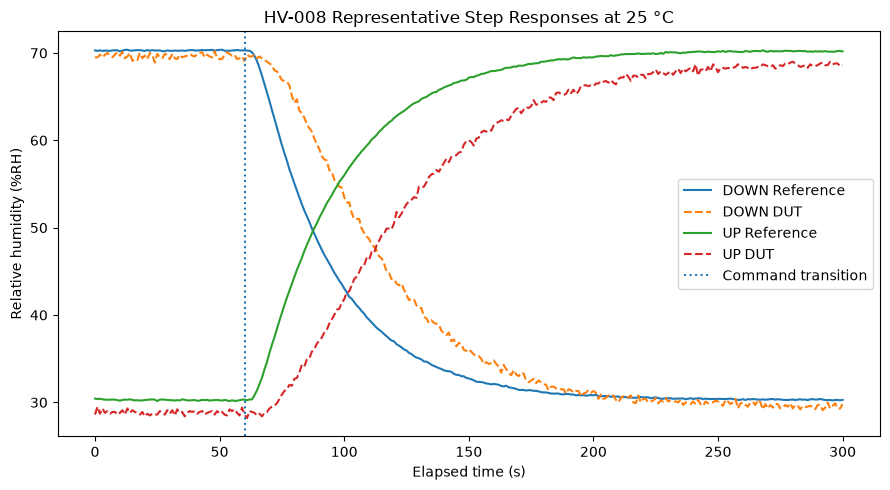

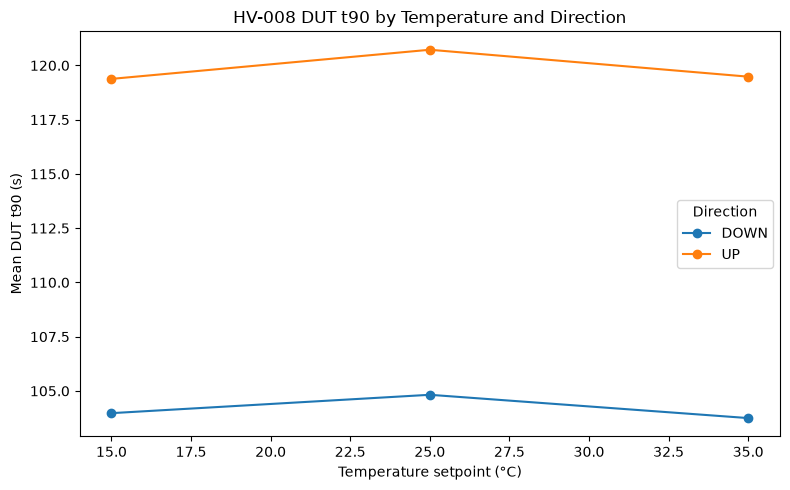

Curated HV-008 figures exported.


In [9]:
import matplotlib.pyplot as plt

# Representative 25 °C, repetition 1: one UP and one DOWN response.
representative_ids = (
    step_metrics_df.loc[
        (step_metrics_df["Temperature_Setpoint_C"] == 25.0)
        & (step_metrics_df["Repetition"] == 1),
        ["Test_ID", "Direction"],
    ]
    .sort_values("Direction")
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(9, 5))
for _, row in representative_ids.iterrows():
    test = step_df.loc[step_df["Test_ID"] == row["Test_ID"]].sort_values("Elapsed_s")
    ax.plot(
        test["Elapsed_s"],
        test["RH_Reference"],
        label=f"{row['Direction']} Reference",
    )
    ax.plot(
        test["Elapsed_s"],
        test["RH_DUT"],
        linestyle="--",
        label=f"{row['Direction']} DUT",
    )

ax.axvline(60.0, linestyle=":", label="Command transition")
ax.set_xlabel("Elapsed time (s)")
ax.set_ylabel("Relative humidity (%RH)")
ax.set_title("HV-008 Representative Step Responses at 25 °C")
ax.legend()
fig.tight_layout()
fig.savefig(
    figures_dir / "hv008_representative_step_response.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for direction, group in condition_summary_df.groupby("Direction"):
    ax.plot(
        group["Temperature_Setpoint_C"],
        group["DUT_t90_s_Mean"],
        marker="o",
        label=direction,
    )

ax.set_xlabel("Temperature setpoint (°C)")
ax.set_ylabel("Mean DUT t90 (s)")
ax.set_title("HV-008 DUT t90 by Temperature and Direction")
ax.legend(title="Direction")
fig.tight_layout()
fig.savefig(
    figures_dir / "hv008_t90_by_condition.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Curated HV-008 figures exported.")